# 作业 3：NumPy、Matplotlib 与 pandas

**学号**：20244080134　**姓名**：平吉佳

In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080134

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境 ] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[ 学号 ]       {STUDENT_ID}")
print(f"[ 机器指纹 ] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境 ] exp_env
[ 学号 ]       20244080134
[ 机器指纹 ] bdba4bb6344f9593
[RUN_ID]   20244080134-bdba4bb6344f9593


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

## 1 半圆定律与随机 Wigner 矩阵

对 $n \times n$ 对称随机矩阵 $Z$：对所有 $1 \le i \le j \le n$，独立地从均值为 $0$、方差为 $1/n$ 的正态分布抽取 $Z_{ij}$，再令 $Z_{ji} = Z_{ij}$。这样的矩阵称为 **Wigner 矩阵**，随着 $n$ 增大，其特征值的分布趋近半圆密度

$$f(x)=\begin{cases}\dfrac{1}{2\pi}\sqrt{4-x^2}, & |x| \le 2,\\[4pt] 0, & |x| > 2.\end{cases}$$

In [ ]:
def wigner_density(x):
    """半圆密度 f(x) = 1/(2π)·√(4-x²) 当 |x|≤2，否则为 0。
    接受 Python 或 NumPy 的整数/浮点数，返回 Python 浮点数。"""
    if abs(x) > 2:
        return 0.0
    return float(np.sqrt(4 - x**2) / (2 * np.pi))


# 测试：Python 与 NumPy 的整数、浮点数
print(wigner_density(0))             # 峰值 1/π ≈ 0.3183
print(wigner_density(1.5))
print(wigner_density(np.float64(1.5)))
print(wigner_density(np.int64(0)))
print(wigner_density(3))             # |x| > 2 -> 0.0

0.3183098861837907
0.2105421996738962
0.2105421996738962
0.3183098861837907
0.0


In [4]:
def generate_wigner(n):
    """生成 n×n Wigner 矩阵：上三角（含对角线）元素独立取自 N(0, 1/n)，再对称化。"""
    if not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")
    W = np.zeros((n, n))
    iu = np.triu_indices(n)
    # 方差为 1/n，即标准差为 1/sqrt(n)
    W[iu] = np.random.normal(0.0, 1.0 / np.sqrt(n), size=len(iu[0]))
    W[(iu[1], iu[0])] = W[iu]
    return W


# 测试：对称性与异常输入
W3 = generate_wigner(3)
print(W3)
print("对称:", np.allclose(W3, W3.T))
for bad in (-2, 0, 2.5):
    try:
        generate_wigner(bad)
    except (ValueError, TypeError) as e:
        print(f"n = {bad}: {type(e).__name__}: {e}")

[[ 0.73067309 -0.30615539  0.89030414]
 [-0.30615539  0.69404275 -0.2598932 ]
 [ 0.89030414 -0.2598932  -0.63134734]]
对称: True
n = -2: ValueError: n 必须是正整数
n = 0: ValueError: n 必须是正整数
n = 2.5: TypeError: n 必须是整数


In [5]:
def get_spectrum(matrix):
    """返回矩阵全部特征值构成的 NumPy 数组，按非递减顺序排列。"""
    return np.sort(np.linalg.eigvalsh(matrix))


# 测试
print(get_spectrum(np.diag([3.0, 1.0, 2.0])))   # [1. 2. 3.]

[1. 2. 3.]


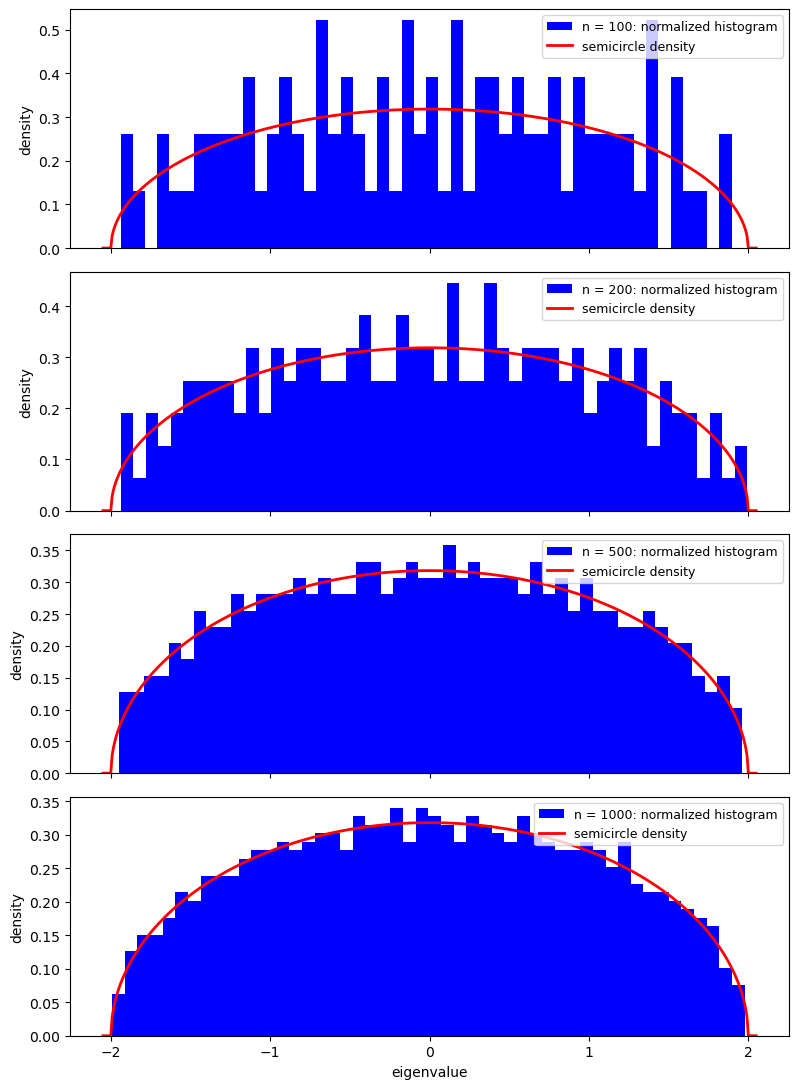

In [6]:
ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(len(ns), 1, figsize=(8, 11), sharex=True)
x = np.linspace(-2.05, 2.05, 500)

for ax, n in zip(axes, ns):
    evals = get_spectrum(generate_wigner(n))
    ax.hist(evals, bins=50, density=True, color="blue",
            label=f"n = {n}: normalized histogram")
    ax.plot(x, [wigner_density(xi) for xi in x], color="red", lw=2, label="semicircle density")
    ax.set_ylabel("density")
    ax.legend(loc="upper right", fontsize=9)

axes[-1].set_xlabel("eigenvalue")
plt.tight_layout()
plt.show()

In [7]:
def semicircle_cdf(x):
    """半圆分布的累积分布函数（用于 KS 检验）。"""
    x = np.asarray(x, dtype=float)
    res = np.empty_like(x)
    lo = x <= -2
    hi = x >= 2
    mid = ~(lo | hi)
    res[lo] = 0.0
    res[hi] = 1.0
    res[mid] = (x[mid] * np.sqrt(4 - x[mid]**2)) / (4 * np.pi) + np.arcsin(x[mid] / 2) / np.pi + 0.5
    return res


# 可选任务：KS 检验（特征值并非独立样本，p 值仅作直观参考）
for n in ns:
    evals = get_spectrum(generate_wigner(n))
    stat, p = stats.kstest(evals, semicircle_cdf)
    print(f"n = {n:5d}: KS statistic = {stat:.4f}, p-value = {p:.4f}")

n =   100: KS statistic = 0.0183, p-value = 1.0000
n =   200: KS statistic = 0.0133, p-value = 1.0000
n =   500: KS statistic = 0.0066, p-value = 1.0000
n =  1000: KS statistic = 0.0027, p-value = 1.0000


**结论**：$n=100$ 时直方图波动明显；$n=200$ 时轮廓已接近半圆；$n=500$ 时除端点附近的随机波动外，直方图与半圆曲线已拟合得很好；$n=1000$ 时几乎完全重合。因此 **$n$ 大约达到 500 时，半圆密度已能较好地拟合特征值分布**，KS 统计量随 $n$ 增大递减也印证了这一点。

## 2 Conway 的生命游戏

棋盘为 $m \times n$ 的 NumPy 二维数组：活细胞记为 1，死细胞记为 0。每一步按以下规则同时更新所有细胞：

- 活细胞：活邻居少于 2 个（死亡）或多于 3 个（死亡）；有 2〜3 个活邻居则继续存活；
- 死细胞：恰好有 3 个活邻居时复活，否则保持死亡。

每个细胞有 8 个邻居（上、下、左、右和四个对角方向），棋盘采用环绕边界。

In [8]:
def is_valid_board(board):
    """若 board 是有效棋盘（二维 NumPy ndarray 且元素仅为 0/1）返回 True，否则返回 False。"""
    if not isinstance(board, np.ndarray) or board.ndim != 2:
        return False
    return bool(np.all((board == 0) | (board == 1)))


# 测试
print(is_valid_board(np.array([[1, 0], [0, 1]])))   # True
print(is_valid_board(np.array([[1, 2], [0, 1]])))   # False（含非 0/1 元素）
print(is_valid_board(np.array([1, 0, 1])))          # False（一维）
print(is_valid_board([[1, 0], [0, 1]]))             # False（非 ndarray）

True
False
False
False


In [9]:
def gol_step(board):
    """返回下一步棋盘（与输入同样大小）；边界环绕，更新只依赖原棋盘。"""
    if not is_valid_board(board):
        raise ValueError("board 必须是元素仅为 0/1 的二维 NumPy 数组")
    neighbors = np.zeros(board.shape, dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)
    alive = board == 1
    stay = alive & ((neighbors == 2) | (neighbors == 3))
    born = (~alive) & (neighbors == 3)
    return (stay | born).astype(int)


# 测试：闪灯（blinker）振荡器
b = np.zeros((5, 5), dtype=int)
b[2, 1:4] = 1
print("blinker:")
print(b)
print(gol_step(b))

blinker:
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]


In [10]:
def draw_gol_board(board):
    """把棋盘画成 m×n 个方格：活细胞黑色、死细胞白色；不显示网格线、轴标签与刻度。"""
    plt.imshow(board, cmap=plt.get_cmap("binary"), vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    plt.show()

step 0


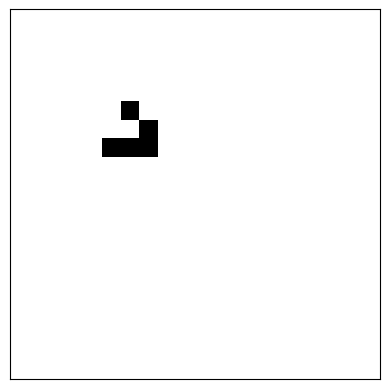

step 1


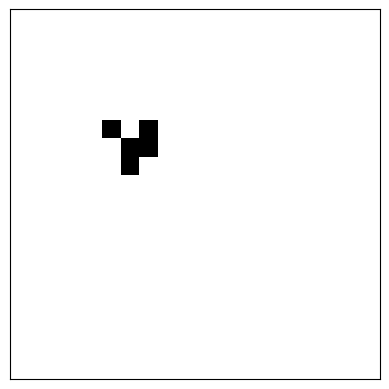

step 2


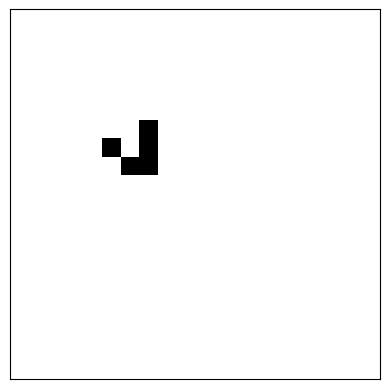

step 3


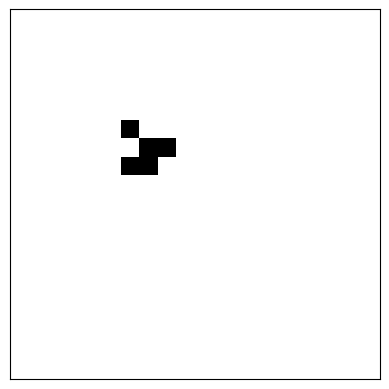

step 4


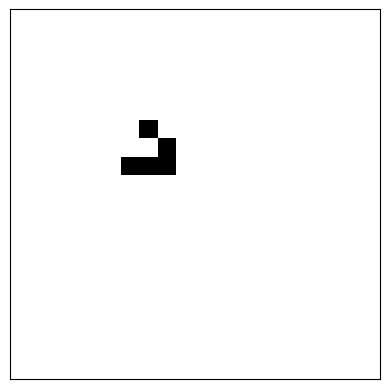

In [11]:
# 演示：滑翔机在 20×20 环绕棋盘上运动（周期为 4 步）
board = np.zeros((20, 20), dtype=int)
glider = np.array([[0, 1, 0],
                   [0, 0, 1],
                   [1, 1, 1]])
board[5:8, 5:8] = glider

print("step 0")
draw_gol_board(board)
for step in range(1, 5):
    board = gol_step(board)
    print(f"step {step}")
    draw_gol_board(board)

## 3 使用 pandas DataFrame

从 `iris.csv` 读入数据，修正两处已知错误行，添加两个比率特征，保存为 `iris_corrected.csv`，并按花卉种类分组汇总。

In [12]:
df = pd.read_csv("iris.csv")

print("数据点个数（行数）:", len(df))
print("列名:", list(df.columns))
print()
print("每列的数据类型:")
print(df.dtypes)
print()
print("花卉种类:", df["species"].nunique(), "种 ->", sorted(df["species"].unique()))
print()
df.head()

数据点个数（行数）: 150
列名: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

每列的数据类型:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

花卉种类: 3 种 -> ['setosa', 'versicolor', 'virginica']



,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [13]:
print("修改前（第 35、38 个数据行，默认索引 34、37）:")
print(df.iloc[[34, 37]])

# 第 35 行：第四项（petal_width）原值 0.1 有误，应为 0.2
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
# 第 38 行：第二项（sepal_width）、第三项（petal_length）有误，应为 3.6、1.4
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]

print()
print("修改后:")
print(df.iloc[[34, 37]])

修改前（第 35、38 个数据行，默认索引 34、37）:
    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.1  setosa
37           4.9          3.1           1.5          0.1  setosa

修改后:
    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.2  setosa
37           4.9          3.6           1.4          0.1  setosa


In [14]:
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species,Petal.Ratio,Sepal.Ratio
0,5.1,3.5,1.4,0.2,setosa,7.0,1.457143
1,4.9,3.0,1.4,0.2,setosa,7.0,1.633333
2,4.7,3.2,1.3,0.2,setosa,6.5,1.468750
3,4.6,3.1,1.5,0.2,setosa,7.5,1.483871
4,5.0,3.6,1.4,0.2,setosa,7.0,1.388889


In [15]:
df.to_csv("iris_corrected.csv", index=False)
print("已保存 iris_corrected.csv：", len(df), "行 x", len(df.columns), "列")

已保存 iris_corrected.csv： 150 行 x 7 列


In [16]:
df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(["mean", "median", "min", "max", "std"])

Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
species                                             
setosa      1.463063  1.268293  1.956522  0.118750  
versicolor  2.161290  1.764706  2.818182  0.228658  
virginica   2.169540  1.823529  2.961538  0.246992